# Modul 379 · Quartiera AG: Was stört unsere Gäste wirklich?

**Ziel:** Mit 5'000 Tripadvisor-Bewertungen drei Entscheide der Geschäftsleitung beantworten.

| # | Entscheid | Frage an die Daten | Kennzahl |
|---|---|---|---|
| 1 | Wohin fliessen CHF 500'000 Coaching-Budget? | Welche Themen nennen unzufriedene Gäste (1–2 Sterne) am häufigsten? | Anteil der unzufriedenen Gäste pro Thema, mit Bandbreite |
| 2 | Fragen wir die richtigen Teilnoten ab? | Welche Themen kosten Sterne, obwohl die 5 Teilnoten sie nicht abbilden? | Zusätzlicher Sterne-Abzug pro Thema (Regression) |
| 3 | Texte automatisch auswerten? | Wie gut erkennt JEV Beschwerden, und wo irrt es sich? | Trefferquote, Präzision, Stabilität, Vergleich mit Stichwort-Methode |

**Vorgehen (hybride Pipeline aus dem Unterricht):** Code bereitet vor → KI (JEV) interpretiert → Code prüft und rechnet → Mensch entscheidet.

Das Notebook liest zwischengespeicherte JEV-Antworten (`data/jev_results.csv`). Den API-Aufruf startet ihr nur neu, wenn ihr `RUN_JEV = True` setzt.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
import codebook, analysis
from analysis import *

## 1 · Daten kennenlernen (HZ 1)

Quelle: *TripAdvisor Review Rating* (Hugging Face `jniimi/tripadvisor-review-rating`, Lizenz Apache-2.0, ursprünglich Li et al. 2013).
201'295 englische Hotelbewertungen aus dem Jahr 2012. Vorgabe: Wir nehmen die **ersten 5'000 Zeilen**.

| Spalte | Art | Bedeutung |
|---|---|---|
| `overall` | quantitativ, ordinal (1–5) | Gesamtnote in Sternen |
| `cleanliness`, `value`, `location`, `rooms`, `sleep_quality` | quantitativ, ordinal (1–5) | die 5 Teilnoten |
| `title`, `text` | **qualitativ** (Freitext) | Nur hier steht, *warum* ein Gast unzufrieden ist |
| `user_id` | Kennung (Pseudonym) | Personendatum → wird entfernt |
| `hotel_id` | Kennung | ⚠️ ist **pro Zeile eindeutig**, also keine echte Hotel-ID |
| `post_date`, `stay_year`, `char`, `lang`, `freq` | Metadaten | Datum, Jahr, Länge, Sprache |

Sterne und Teilnoten zeigen, **dass** etwas schlecht war, aber nur der Text sagt, **warum**.

In [2]:
s = pd.read_csv("../data/sample_5000.csv")
print(s.shape)
s[["overall","cleanliness","value","location","rooms","sleep_quality","char"]].describe().round(2)

(5000, 13)


,overall,cleanliness,value,location,rooms,sleep_quality,char
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,4.05,4.29,3.96,4.46,4.03,4.14,831.74
std,1.08,1.01,1.11,0.84,1.07,1.08,617.58
min,1.00,1.00,1.00,1.00,1.00,1.00,65.00
25%,4.00,4.00,3.00,4.00,3.00,4.00,420.75
50%,4.00,5.00,4.00,5.00,4.00,4.00,668.00
75%,5.00,5.00,5.00,5.00,5.00,5.00,1048.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5630.00


**Ist die Stichprobe «die ersten 5'000» verzerrt?** Ein Vergleich mit dem Gesamtdatensatz (201'295 Zeilen) zeigt dieselbe Verteilung der Sterne:

| Sterne | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| alle 201'295 | 4.0 % | 5.4 % | 14.0 % | 33.6 % | 43.0 % |
| erste 5'000 | 4.1 % | 5.7 % | 13.8 % | 33.7 % | 42.7 % |

Der Datensatz ist nicht nach Hotel oder Note sortiert. Die ersten 5'000 sind deshalb für unsere Zwecke vertretbar.

In [3]:
s.overall.value_counts(normalize=True).sort_index().round(3)

overall
1.0    0.041
2.0    0.057
3.0    0.138
4.0    0.337
5.0    0.427
Name: proportion, dtype: float64

## 2 · Datenqualität (HZ 2)

Geprüft mit `src/prepare.py`: fehlende Werte, Duplikate, unmögliche Werte, Ausreisser (sehr kurze Texte).
Das Protokoll hält fest, wie viele Zeilen betroffen sind und was wir entschieden haben.

In [4]:
pd.read_csv("../data/bereinigungsprotokoll.csv")

,Problem,Anzahl Zeilen,Entscheid
0,Fehlende Werte,0,keine Aktion
1,Doppelter Text,0,entfernt (erste behalten)
2,Note ausserhalb 1-5,0,entfernt
3,Text < 50 Zeichen,0,"behalten, markiert"
4,Texte mit maskierten Namen/Kontakten,79,maskiert vor Versand


**Annahmen, die wir festhalten:**
- Im Gesamtdatensatz gibt es 40 doppelte Texte. In den ersten 5'000 Zeilen kommt keiner davon vor.
- Die Sternverteilung ist schief (76 % geben 4–5 Sterne). Das ist normal für Bewertungsportale. Darum werten wir die unzufriedenen Gäste **separat** aus und nicht im Durchschnitt aller Gäste.
- Sehr lange Texte (bis 22'000 Zeichen) behalten wir. JEV verarbeitet bis 32'000 Tokens pro Frage.

## 3 · Datenschutz vor dem Versand (HZ 4)

- `user_id` und `hotel_id` werden **nicht** gespeichert und nicht verschickt.
- Namen nach Anrede oder «named …», E-Mail-Adressen und Telefonnummern werden maskiert (`src/privacy.py`).
- **Grenze:** Vornamen ohne Anrede (z.B. «thanks to Maria») erkennt die Regel nicht. Darum verwenden wir im Report **keine Zitate**, die nicht von Hand kontrolliert sind.

In [5]:
from privacy import mask
beispiel = "The night manager Mr Smith was rude, call him at +1 312 555 0199 or smith@hotel.com"
print(mask(beispiel))
print("Bewertungen mit Maskierung:", int(s.masked_changes.sum()))

The night manager Mr [NAME] was rude, call him at [TEL] or [EMAIL]
Bewertungen mit Maskierung: 79


## 4 · Vom Text zur Zahl: das Codebuch für JEV (HZ 1 + 2)

JEV (TypeSafe) beantwortet **Noul-Fragen**: Für jede Aussage liefert es eine Wahrscheinlichkeit von 0 bis 1, dass sie stimmt.
Pro Bewertung stellen wir 17 Fragen in **einer** Anfrage: 1× «irgendeine Beschwerde» und 16 Themen.

Regeln aus der JEV-Doku, die wir umsetzen:
- Fragen eng und wörtlich formulieren (JEV liest wörtlich).
- Zählen und Rechnen macht der Code, nicht JEV.
- Schwellen: ≥ 0.7 = ja, ≤ 0.3 = nein, dazwischen = **unsicher**. Für Zählungen verwenden wir 0.5 und zeigen die Unsicherheit als Bandbreite.

Spalte «Teilnote» = welche der 5 heutigen Teilnoten das Thema abdeckt (leer = wird heute nicht abgefragt).

In [6]:
pd.DataFrame([(k, v[0], v[1] or "– nicht abgefragt –", v[2]) for k, v in codebook.THEMES.items()],
             columns=["Code", "Thema", "Teilnote", "Frage an JEV"])

,Code,Thema,Teilnote,Frage an JEV
0,complaint,Beschwerde (irgendeine),– nicht abgefragt –,"The guest describes at least one problem, comp..."
1,staff_service,Personal & Service,– nicht abgefragt –,The guest complains about hotel staff or servi...
2,checkin_booking,"Check-in, Reservation & Rechnung",– nicht abgefragt –,"The guest complains about check-in, check-out,..."
3,cleanliness,Sauberkeit & Geruch,cleanliness,"The guest complains that the room, bathroom, b..."
4,pests,Ungeziefer (Bettwanzen etc.),cleanliness,"The guest reports bed bugs, cockroaches, mice ..."
5,room_condition,"Zustand: alt, abgenutzt, defekt",rooms,The guest complains that the room or hotel is ...
6,room_size,Zimmer zu klein,rooms,The guest complains that the room was too smal...
7,bathroom_plumbing,"Bad, Dusche, Wasser",rooms,"The guest complains about the bathroom, shower..."
8,ac_heating,Klimaanlage & Heizung,rooms,"The guest complains about air conditioning, he..."
9,noise,Lärm,sleep_quality,The guest complains about noise: from other gu...


### JEV aufrufen (nur bei Bedarf)

Kosten des vollen Laufs: ca. 4.6 Mio. Tokens × $0.042 pro Mio. = **ca. 20 Rappen**. Dauer: ein paar Minuten.
Der API-Key kommt aus der Umgebungsvariable `TYPESAFE_API_KEY` und steht **nie** im Notebook.

In [7]:
RUN_JEV = False   # auf True setzen, um JEV neu zu befragen
if RUN_JEV:
    assert os.environ.get("TYPESAFE_API_KEY"), "Bitte TYPESAFE_API_KEY setzen"
    !python ../src/run_jev.py ../data/sample_5000.csv ../data/jev_results.csv
df = load()
print(len(df), "Bewertungen mit JEV-Antworten")
df[["review_id","overall","title_masked","complaint","staff_service","cleanliness","noise"]].head(8)

5000 Bewertungen mit JEV-Antworten


,review_id,overall,title_masked,complaint,staff_service,cleanliness,noise
0,0,5.0,Really excellent Hilton,0.02,0.02,0.02,0.02
1,1,5.0,Exceptional service and comfort,0.97,0.02,0.02,0.02
2,2,5.0,Nice room and five star service,0.95,0.02,0.03,0.26
3,3,5.0,"BRILLIANT hotel, my #1 Chicago pick for busine...",0.03,0.02,0.02,0.02
4,4,5.0,Convenient and comfortable,0.03,0.02,0.02,0.03
5,5,4.0,Our Stay at The Parc 55,0.97,0.03,0.03,0.94
6,6,2.0,Would Avoid If Possible,0.99,0.96,0.04,0.04
7,7,4.0,Second Visit,0.15,0.03,0.02,0.05


## 5 · Überprüfung: Stimmt die Methode? (HZ 3)

Bevor wir den Zahlen glauben, prüfen wir JEV auf vier Arten:

1. **Plausibilität mit den Teilnoten:** Wenn JEV «Sauberkeits-Beschwerde» meldet, muss die Sauberkeits-Note tiefer sein.
2. **Kontrollstichprobe:** 100 Bewertungen (50 mit 1–2, 25 mit 3, 25 mit 4–5 Sternen, zufällig, gemischt) wurden **unabhängig von JEV und vor dem Blick auf die JEV-Resultate** codiert. Diese Referenz hat das KI-Werkzeug Claude erstellt (siehe Grenzen). ➜ Vorlage `data/gold_100_eure_kontrolle.csv`: Prüft mindestens 30 davon selbst.
3. **Stabilität:** 200 Bewertungen ein zweites Mal an JEV geschickt.
4. **Vergleich mit einer einfachen Stichwort-Methode** (Regex), damit wir sehen, ob sich die KI lohnt.

In [8]:
convergent_validity(df).round(2)

,Thema,Teilnote,note_mit_beschwerde,note_ohne_beschwerde,n_mit
0,Sauberkeit & Geruch,Sauberkeit,2.31,4.50,478
1,Ungeziefer (Bettwanzen etc.),Sauberkeit,1.85,4.32,46
2,"Zustand: alt, abgenutzt, defekt",Zimmer,2.75,4.30,872
3,Zimmer zu klein,Zimmer,3.01,4.13,455
4,"Bad, Dusche, Wasser",Zimmer,3.01,4.16,589
5,Klimaanlage & Heizung,Zimmer,3.14,4.08,288
6,Lärm,Schlaf,3.03,4.31,675
7,Bett & Kissen,Schlaf,2.48,4.20,181
8,Preis & Zusatzgebühren,Preis-Leistung,2.66,4.18,718
9,Lage & Sicherheit der Umgebung,Lage,2.82,4.56,264


➜ **Plausibel:** Bei jedem Thema ist die passende Teilnote deutlich tiefer, wenn JEV eine Beschwerde meldet.
Beispiel Sauberkeit: 2.3 statt 4.5 Sterne. JEV misst also, was es messen soll.

In [9]:
d3, stab, tot, gold_merged = decision3(df)
cols = ["Thema","ref_ja","jev_TP","jev_FP","jev_FN","jev_praezision","jev_trefferquote","jev_f1","kw_f1","unsicher"]
d3[cols].round(2)

,Thema,ref_ja,jev_TP,jev_FP,jev_FN,jev_praezision,jev_trefferquote,jev_f1,kw_f1,unsicher
0,Beschwerde (irgendeine),89,89,0,0,1.00,1.00,1.00,0.94,0.01
1,Personal & Service,28,28,11,0,0.72,1.00,0.84,0.57,0.13
2,"Check-in, Reservation & Rechnung",21,15,2,6,0.88,0.71,0.79,0.57,0.10
3,Sauberkeit & Geruch,24,23,3,1,0.88,0.96,0.92,0.87,0.06
4,Ungeziefer (Bettwanzen etc.),3,3,0,0,1.00,1.00,1.00,0.80,0.00
5,"Zustand: alt, abgenutzt, defekt",36,32,13,4,0.71,0.89,0.79,0.61,0.12
6,Zimmer zu klein,17,17,1,0,0.94,1.00,0.97,0.69,0.03
7,"Bad, Dusche, Wasser",17,16,4,1,0.80,0.94,0.86,0.60,0.09
8,Klimaanlage & Heizung,8,8,7,0,0.53,1.00,0.70,0.30,0.05
9,Lärm,31,30,0,1,1.00,0.97,0.98,0.92,0.03


In [10]:
print("Stabilität:", stab)
print(pd.DataFrame(tot).T[["praezision","trefferquote","f1","genauigkeit"]].round(2))

Stabilität: {'entscheide': 3400, 'gekippt': 6, 'max_abweichung': 0.09999999999999998}
              praezision  trefferquote    f1  genauigkeit
JEV                 0.81          0.91  0.86         0.94
Stichwoerter        0.61          0.67  0.64         0.86


**So liest man das:**
- *Trefferquote* = Von allen echten Beschwerden zu einem Thema: Wie viele findet JEV?
- *Präzision* = Von allen JEV-Meldungen: Wie viele stimmen?
- *F1* = Mittelwert aus beiden (1.0 = perfekt).

**Ergebnis:** Über alle 16 Themen erreicht JEV F1 = 0.86 (Präzision 81 %, Trefferquote 91 %). Die Stichwort-Methode schafft nur 0.64.
Im zweiten Durchlauf kippen nur 6 von 3'400 Entscheiden, und zwar alle nahe der 50 %-Grenze.

**Wo JEV sich irrt** (Fehler von Hand angeschaut):
- **Fehlalarme bei überlappenden Themen:** Eine defekte Klimaanlage zählt JEV auch als «Zustand defekt», Abrechnungsprobleme auch als «Preis», schlechte Reinigung auch als «Personal». Das ist oft eher eine Unschärfe im Codebuch als ein KI-Fehler.
- **Übersehen bei indirekten Aussagen:** «nicht viel in der Umgebung», «Polizei vor dem Haus» (Lage) oder «Nichtraucher-Zimmer versprochen, Raucherzimmer bekommen» (Reservation) erkennt JEV schlechter.

In [11]:
complaint_by_stars(df).round(3)

,n,anteil_beschwerde,anteil_unsicher
overall,,,
1.0,206,1.000,0.000
2.0,286,1.000,0.000
3.0,690,0.975,0.012
4.0,1684,0.745,0.071
5.0,2134,0.346,0.090


⚠️ **Wichtig für Entscheid 3:** «Irgendeine Beschwerde» steckt auch in 35 % der 5-Sterne-Bewertungen («super Hotel, nur das Frühstück war teuer»).
Wer *alles* weiterleitet, überflutet die Hotels. Weiterleiten sollte man nur nach **Thema + Sternen** (oder einem zusätzlichen Score für den Schweregrad).

## 6 · Entscheid 1: Was stört unzufriedene Gäste am meisten?

Basis: alle 492 Bewertungen mit 1–2 Sternen. Die **Bandbreite** verbindet zwei Unsicherheiten:
- Stichprobenzufall (95 %-Wilson-Intervall)
- KI-Unsicherheit (untere Grenze: nur sichere Ja ≥ 0.7, obere Grenze: alles ausser sicheren Nein > 0.3)

«Faktor» = wie viel häufiger das Thema bei unzufriedenen als bei zufriedenen Gästen vorkommt.

In [12]:
d1 = decision1(df)
d1[["Thema","Teilnote","anteil_unzufrieden","von","bis","anzahl","anteil_zufrieden","faktor"]].round(2)

,Thema,Teilnote,anteil_unzufrieden,von,bis,anzahl,anteil_zufrieden,faktor
0,Personal & Service,- (nicht abgefragt),0.66,0.54,0.73,326,0.06,10.86
1,"Zustand: alt, abgenutzt, defekt",Zimmer,0.62,0.50,0.73,306,0.06,10.28
2,Sauberkeit & Geruch,Sauberkeit,0.51,0.42,0.59,251,0.02,23.75
3,Preis & Zusatzgebühren,Preis-Leistung,0.45,0.34,0.55,222,0.07,6.04
4,"Bad, Dusche, Wasser",Zimmer,0.36,0.27,0.43,178,0.06,6.06
5,Lärm,Schlaf,0.31,0.26,0.36,154,0.08,3.76
6,"Check-in, Reservation & Rechnung",- (nicht abgefragt),0.29,0.19,0.39,144,0.04,8.10
7,"Frühstück, Restaurant, Bar",- (nicht abgefragt),0.25,0.18,0.32,123,0.10,2.42
8,"Einrichtungen (Pool, Gym, Lift, Lobby)",- (nicht abgefragt),0.21,0.11,0.29,105,0.06,3.57
9,Klimaanlage & Heizung,Zimmer,0.18,0.13,0.22,87,0.03,5.63


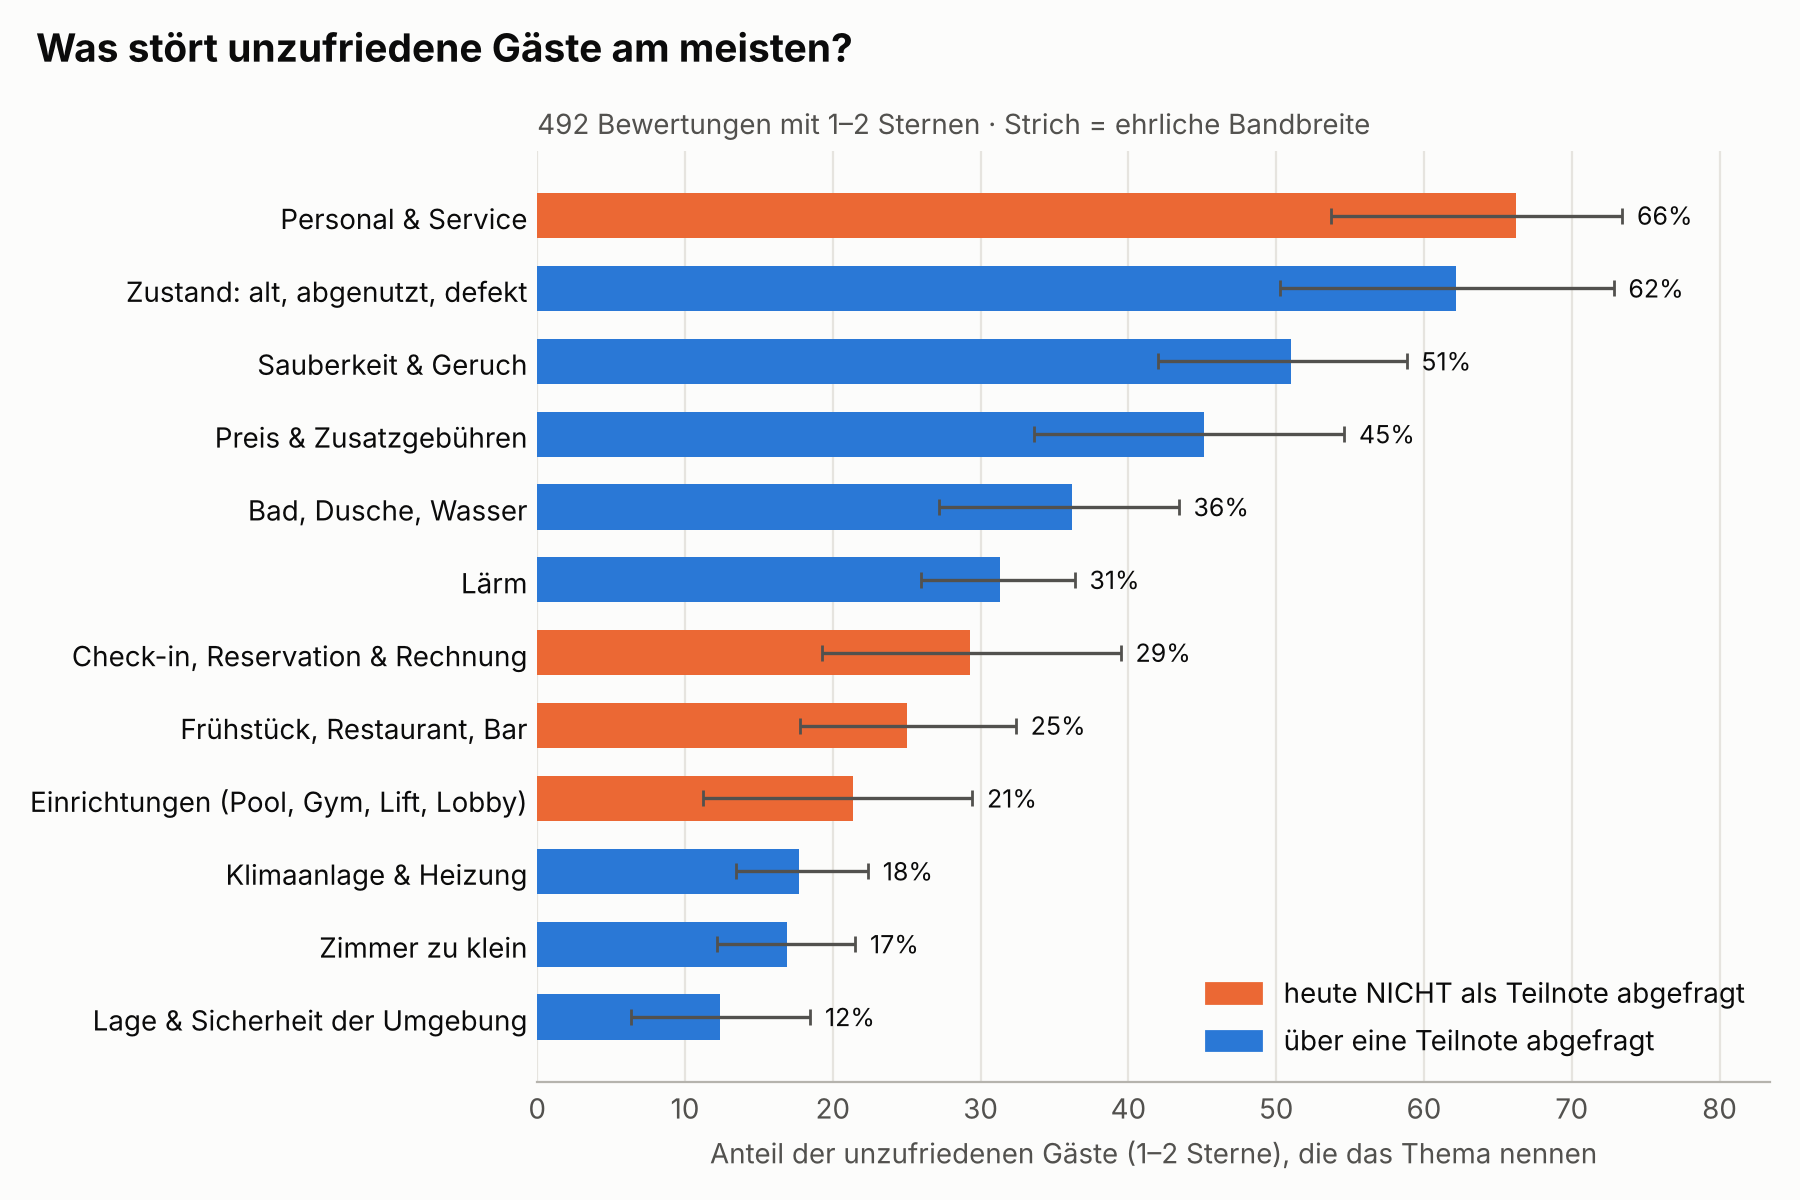

In [13]:
fig1(d1, "../output/grafik1_themen_unzufriedene.png")
display(Image("../output/grafik1_themen_unzufriedene.png", width=800))

**Erkenntnis:** Zwei von drei unzufriedenen Gästen beklagen sich über **Personal & Service** (66 %, Bandbreite 54–73 %). Das ist das häufigste Thema, und es wird heute nicht abgefragt.
Danach folgen Zustand der Zimmer (62 %) und Sauberkeit (51 %). Coaching wirkt vor allem auf Verhalten und Abläufe (Service, Housekeeping, Beschwerdemanagement), weniger auf alte Bausubstanz.

## 7 · Entscheid 2: Fragen wir die richtigen Teilnoten ab?

Regression: `overall ~ 5 Teilnoten (+ 16 Themen)`.
Die 5 Teilnoten allein erklären 78 % der Unterschiede in der Gesamtnote. Was übrig bleibt, zeigt, was die Teilnoten **übersehen**.
Der Koeffizient eines Themas sagt: So viele Sterne weniger gibt ein Gast, wenn er das Thema erwähnt, **bei gleichen Teilnoten**.
Robuste Standardfehler (HC3). Das ist ein Zusammenhang, keine bewiesene Ursache.

In [14]:
d2, fit = decision2(df)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in fit.items()})
d2[["Thema","Teilnote","sterne_effekt","von","bis","p_wert","anteil_alle"]].round(3)

{'r2_a': np.float64(0.781), 'r2_b': np.float64(0.804), 'n': 5000}


,Thema,Teilnote,sterne_effekt,von,bis,p_wert,anteil_alle
0,Ungeziefer (Bettwanzen etc.),Sauberkeit,-0.401,-0.615,-0.188,0.000,0.009
1,Personal & Service,- (nicht abgefragt),-0.385,-0.444,-0.326,0.000,0.161
2,"Zustand: alt, abgenutzt, defekt",Zimmer,-0.161,-0.214,-0.108,0.000,0.174
3,"Einrichtungen (Pool, Gym, Lift, Lobby)",- (nicht abgefragt),-0.112,-0.167,-0.057,0.000,0.092
4,Lage & Sicherheit der Umgebung,Lage,-0.088,-0.166,-0.011,0.025,0.053
5,"Check-in, Reservation & Rechnung",- (nicht abgefragt),-0.070,-0.142,0.002,0.058,0.078
6,"Bad, Dusche, Wasser",Zimmer,-0.061,-0.112,-0.010,0.019,0.118
7,WLAN & Internet,- (nicht abgefragt),-0.053,-0.118,0.011,0.106,0.057
8,Parkieren & Valet,- (nicht abgefragt),-0.047,-0.113,0.018,0.158,0.062
9,Lärm,Schlaf,-0.045,-0.094,0.004,0.069,0.135


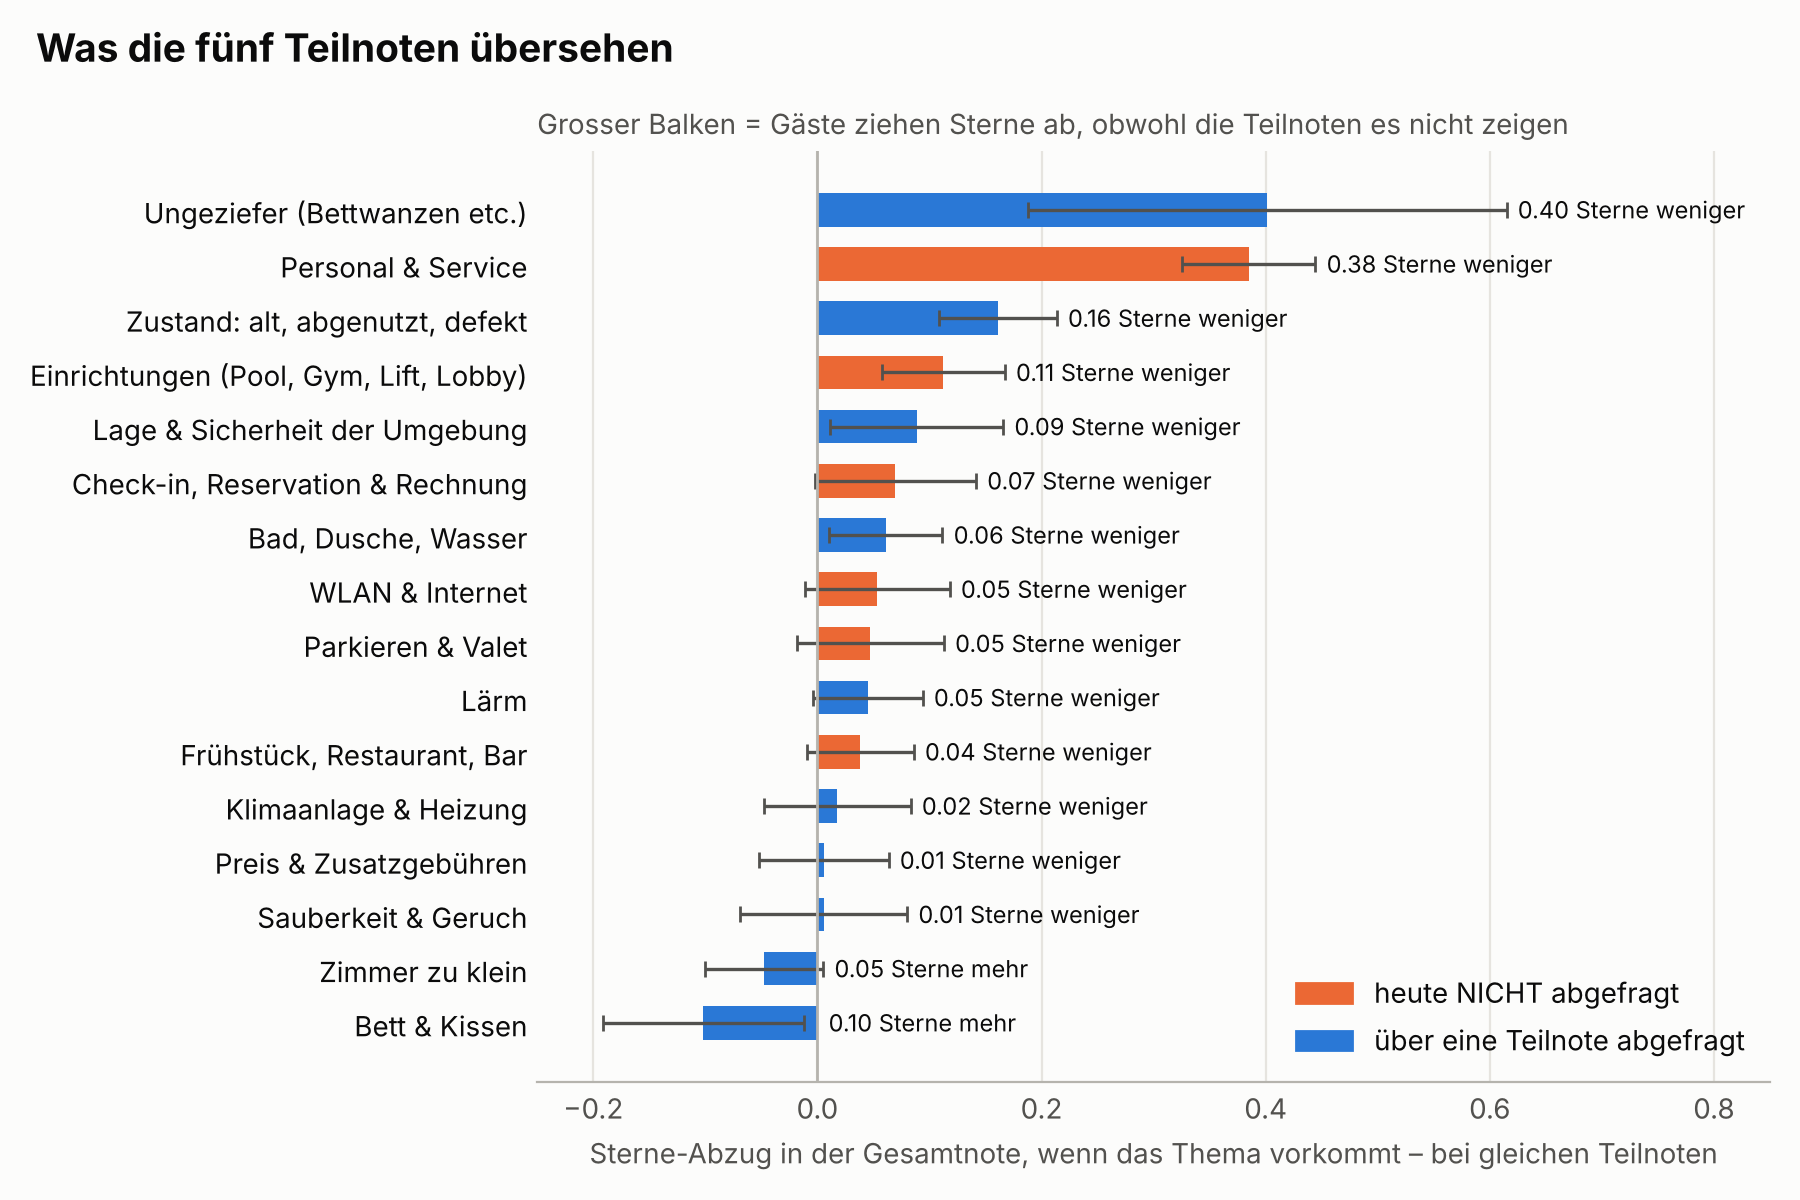

In [15]:
fig2(d2, "../output/grafik2_teilnoten_luecken.png")
display(Image("../output/grafik2_teilnoten_luecken.png", width=800))

**Erkenntnis:** **Personal & Service** kostet zusätzlich 0.38 Sterne (Bandbreite 0.33–0.44, p < 0.001). Es kommt in 16 % aller Bewertungen vor und ist die grösste Lücke im heutigen Fragebogen.
Auch «Einrichtungen» zeigt einen klaren, aber kleinen Effekt (−0.11). Check-in, WLAN, Parkieren und Frühstück sind klein und statistisch nicht gesichert.
Ungeziefer hat zwar den grössten Effekt (−0.40), ist aber selten (0.9 %) und gehört bereits zur Sauberkeit.

## 8 · Entscheid 3: Wie gut erkennt ein KI-Werkzeug Beschwerden?

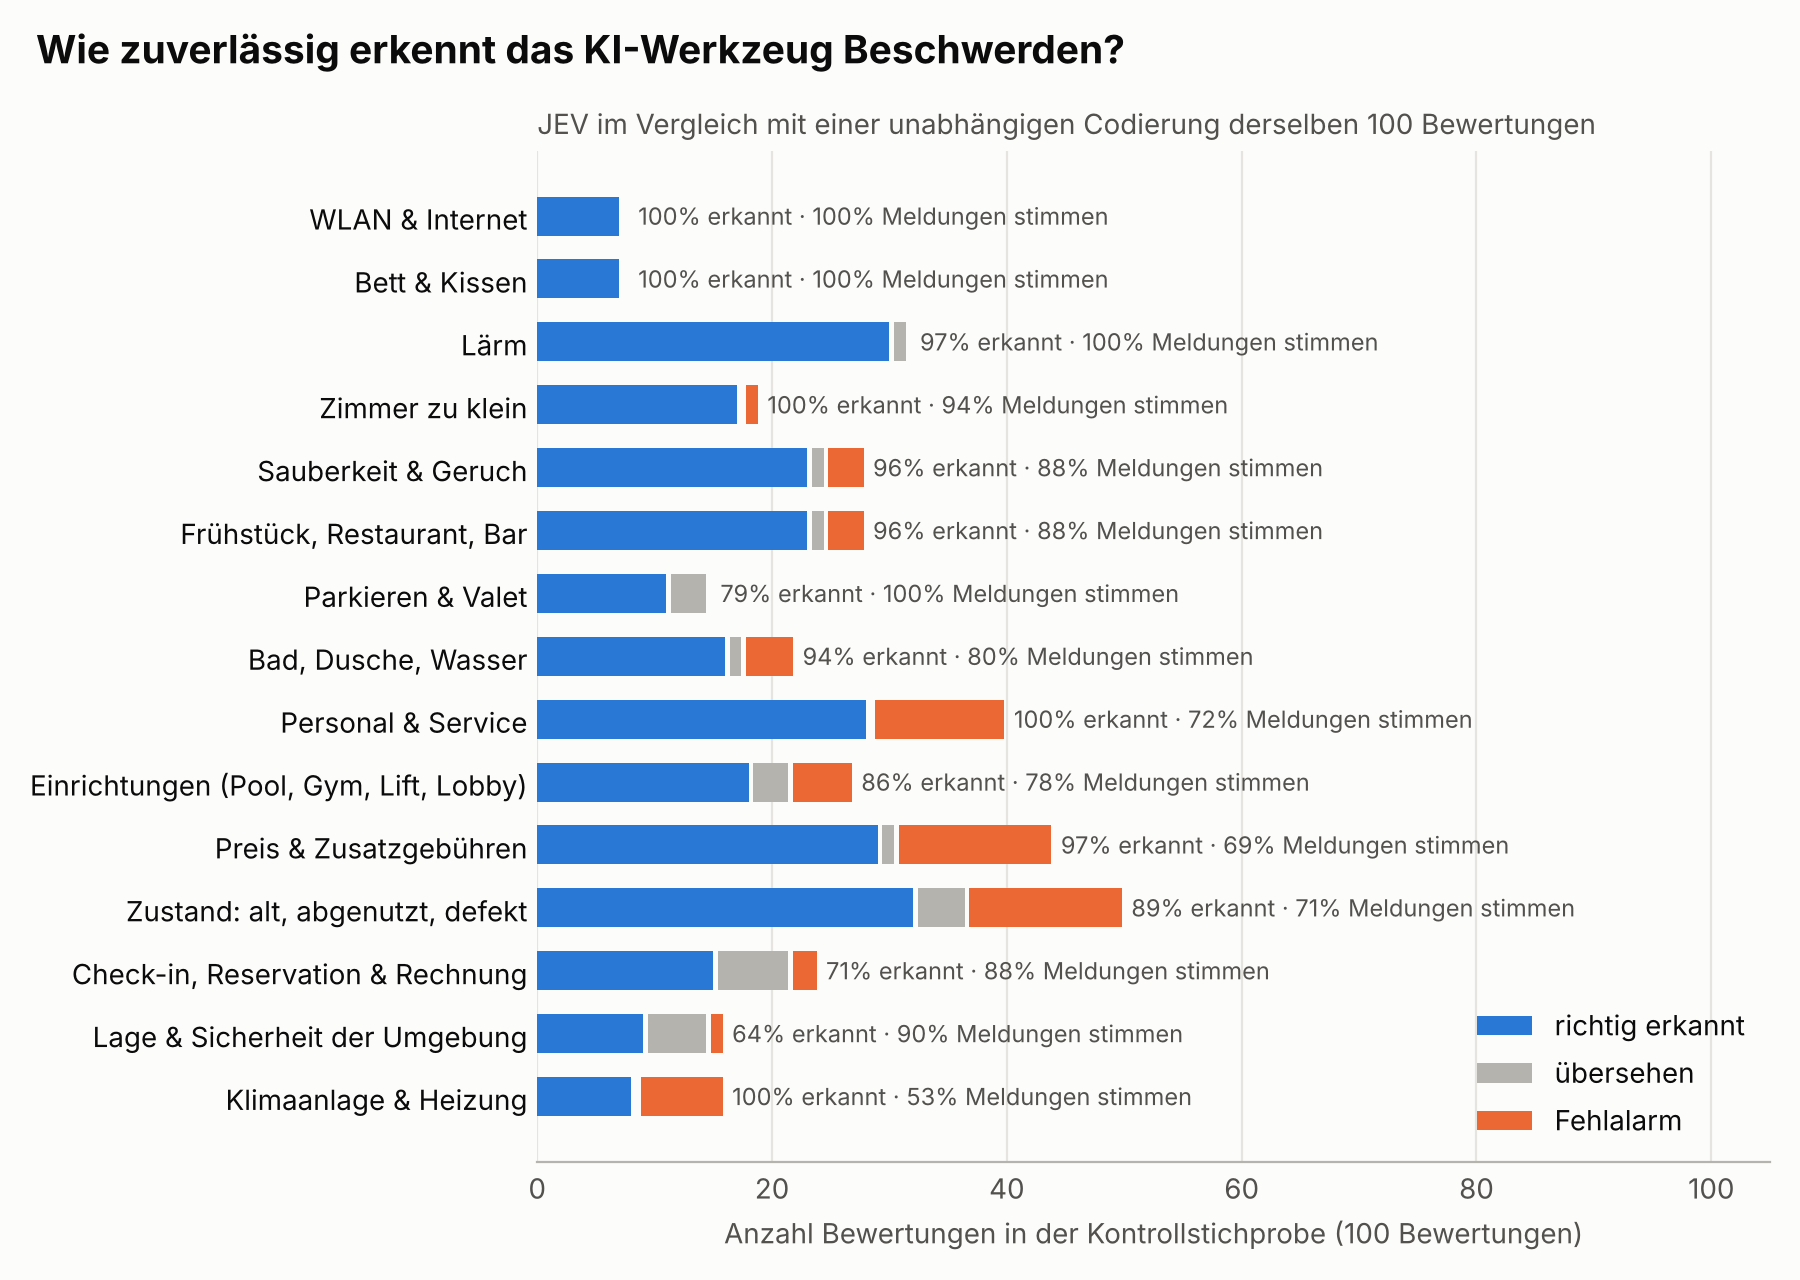

In [16]:
fig3(d3, "../output/grafik3_ki_zuverlaessigkeit.png")
display(Image("../output/grafik3_ki_zuverlaessigkeit.png", width=800))

## 9 · Eure Handkontrolle (Pflicht vor der Präsentation)

Die Referenz für Kapitel 5 hat ein KI-Werkzeug (Claude) codiert. Für eine faire Prüfung muss **ein Mensch** mindestens 30 davon selbst codieren.
Öffnet `data/gold_100_eure_kontrolle.csv` (z.B. in Excel), tragt pro Thema 1/0 ein und lasst diese Zelle laufen.

In [17]:
eure = pd.read_csv("../data/gold_100_eure_kontrolle.csv")
fertig = eure.dropna(subset=["complaint"])
print(len(fertig), "Bewertungen von euch codiert")
if len(fertig) >= 10:
    ref = pd.read_csv("../data/gold_100_claude.csv").set_index("review_id")
    j = df.set_index("review_id")
    rows = []
    for t in codebook.THEMES:
        y = fertig.set_index("review_id")[t].astype(int)
        rows.append(dict(Thema=codebook.LABEL[t],
                         uebereinstimmung_mit_Claude=(y == ref.loc[y.index, t]).mean(),
                         uebereinstimmung_mit_JEV=(y == (j.loc[y.index, t] >= .5).astype(int)).mean()))
    display(pd.DataFrame(rows).round(2))

0 Bewertungen von euch codiert


## 10 · Was die Daten NICHT beantworten können

- **Keine Hotel-Zuordnung:** `hotel_id` ist pro Bewertung eindeutig. Ob Beschwerden «beim richtigen Hotel landen», lässt sich mit diesen Daten nicht testen. Die Zuordnung muss über die Buchungs-ID erfolgen.
- **2012, USA, Englisch, Tripadvisor:** Die Gäste von Quartiera heute können anders sein. Die Ergebnisse sind ein Hinweis, kein Beweis für Partnerhotels.
- **Wer schreibt, ist nicht repräsentativ:** Sehr zufriedene und sehr unzufriedene Gäste schreiben häufiger.
- **Ursache vs. Zusammenhang:** Dass Service-Beschwerden mit tieferen Noten einhergehen, beweist nicht, dass ein Coaching die Note hebt. Das zeigt erst ein Pilot mit Vorher-Nachher-Messung.
- **Stichprobe:** 5'000 von 201'295 (492 unzufriedene). Seltene Themen (Ungeziefer: 46 Fälle) sind unsicher.
- **Referenz durch eine KI:** Die Kontrollstichprobe ist (noch) nicht von Menschen codiert, siehe Kapitel 9.